In [13]:
import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn

device = "cuda" if torch.cuda.is_available() else "cpu"
env = gym.make("CartPole-v1")

def make_policy():
    return nn.Sequential(
        nn.Linear(4, 128), nn.ReLU(),
        nn.Linear(128, 2),          # logits, one per action
    ).to(device)

policy = make_policy()

s, _ = env.reset(seed=0)
logits = policy(torch.tensor(s, dtype=torch.float32, device=device))
dist = torch.distributions.Categorical(logits=logits)
print("logits:", logits)
print("probs :", dist.probs)
print("sample:", dist.sample().item())
print("logprob:", dist.log_prob(dist.sample()))


logits: tensor([-0.0006, -0.1220], device='cuda:0', grad_fn=<ViewBackward0>)
probs : tensor([0.5303, 0.4697], device='cuda:0', grad_fn=<SoftmaxBackward0>)
sample: 1
logprob: tensor(-0.6343, device='cuda:0', grad_fn=<SqueezeBackward1>)


In [14]:
def act(policy, s):
    """Returns (action:int, log_prob:tensor) — keep the tensor, it needs a gradient."""
    s = torch.tensor(s, dtype=torch.float32, device=device)
    logits = policy(s)
    dist = torch.distributions.Categorical(logits=logits)
    a = dist.sample()
    return a.item(), dist.log_prob(a)

In [15]:
def reinforce(n_episodes=1500, gamma=0.99, lr=1e-3, normalize=True, seed=0):
    torch.manual_seed(seed)
    env = gym.make("CartPole-v1")
    policy = make_policy()
    opt = torch.optim.Adam(policy.parameters(), lr=lr)
    log = []

    for ep in range(n_episodes):
        s, _ = env.reset()
        log_probs, rewards = [], []
        done = False
        while not done:
            a, lp = act(policy, s)
            s, r, term, trunc, _ = env.step(a)
            log_probs.append(lp)
            rewards.append(r)
            done = term or trunc

        G, Gs = 0.0, []
        for r in reversed(rewards):
            G = r + gamma * G
            Gs.append(G)
        Gs = list(reversed(Gs))
        Gs = torch.tensor(Gs, dtype=torch.float32, device=device)
        if normalize:
            Gs = (Gs - Gs.mean()) / (Gs.std() + 1e-8)

        loss = -(torch.stack(log_probs) * Gs).sum()
        opt.zero_grad()
        loss.backward()
        opt.step()

        log.append(sum(rewards))
        if (ep + 1) % 50 == 0:
            print(f"ep {ep+1:4d}  avg50={np.mean(log[-50:]):6.1f}")

    return policy, log

policy, log = reinforce()

ep   50  avg50=  21.8
ep  100  avg50=  32.9
ep  150  avg50=  44.2
ep  200  avg50=  99.8
ep  250  avg50= 146.7
ep  300  avg50= 139.9
ep  350  avg50= 190.4
ep  400  avg50= 188.8
ep  450  avg50= 255.4
ep  500  avg50= 209.5
ep  550  avg50= 300.9
ep  600  avg50= 359.1
ep  650  avg50= 431.1
ep  700  avg50= 411.0
ep  750  avg50= 455.6
ep  800  avg50= 467.5
ep  850  avg50= 488.6
ep  900  avg50= 479.6
ep  950  avg50= 389.0
ep 1000  avg50= 365.7
ep 1050  avg50= 470.9
ep 1100  avg50= 478.3
ep 1150  avg50= 477.1
ep 1200  avg50= 463.0
ep 1250  avg50= 485.1
ep 1300  avg50= 485.3
ep 1350  avg50= 496.3
ep 1400  avg50= 495.6
ep 1450  avg50= 495.9
ep 1500  avg50= 495.4


In [16]:
policy, log = reinforce(normalize=False)

ep   50  avg50=  22.2
ep  100  avg50=  33.2
ep  150  avg50=  54.1
ep  200  avg50=  63.6
ep  250  avg50=  89.6
ep  300  avg50= 137.3
ep  350  avg50= 135.3
ep  400  avg50= 201.4
ep  450  avg50= 230.5
ep  500  avg50= 328.7
ep  550  avg50= 327.5
ep  600  avg50= 326.5
ep  650  avg50= 355.3
ep  700  avg50= 362.2
ep  750  avg50= 362.1
ep  800  avg50= 339.9
ep  850  avg50= 265.1
ep  900  avg50= 329.4
ep  950  avg50= 370.1
ep 1000  avg50= 416.8
ep 1050  avg50= 468.5
ep 1100  avg50= 462.7
ep 1150  avg50= 487.8
ep 1200  avg50= 474.4
ep 1250  avg50= 497.6
ep 1300  avg50= 481.0
ep 1350  avg50= 467.2
ep 1400  avg50= 359.1
ep 1450  avg50= 276.6
ep 1500  avg50= 386.2


In [26]:
def make_value():
    return nn.Sequential(
        nn.Linear(4, 128), nn.ReLU(),
        nn.Linear(128, 1),
    ).to(device)


def reinforce_baseline(n_episodes=1500, gamma=0.99, lr=1e-3, lr_v=1e-3, seed=0):
    torch.manual_seed(seed)
    env = gym.make("CartPole-v1")
    policy, value = make_policy(), make_value()
    opt = torch.optim.Adam(policy.parameters(), lr=lr)
    opt_v = torch.optim.Adam(value.parameters(), lr=lr_v)
    log = []

    for ep in range(n_episodes):
        s, _ = env.reset()
        states, log_probs, rewards = [], [], []
        done = False
        while not done:
            a, lp = act(policy, s)
            states.append(s)                     # keep states now
            s, r, term, trunc, _ = env.step(a)
            log_probs.append(lp)
            rewards.append(r)
            done = term or trunc

        G, Gs = 0.0, []
        for r in reversed(rewards):
            G = r + gamma * G
            Gs.append(G)
        Gs = torch.tensor(list(reversed(Gs)), dtype=torch.float32, device=device)
        S = torch.tensor(np.array(states), dtype=torch.float32, device=device)

        V = value(S).squeeze(1)
        adv = (Gs - V).detach()
        policy_loss = -(torch.stack(log_probs) * adv).sum()
        value_loss = nn.functional.mse_loss(V, Gs)

        opt.zero_grad(); policy_loss.backward(); opt.step()
        opt_v.zero_grad(); value_loss.backward(); opt_v.step()

        log.append(sum(rewards))
        if (ep + 1) % 50 == 0:
            print(f"ep {ep+1:4d}  avg50={np.mean(log[-50:]):6.1f}")

    return policy, value, log


In [27]:
policy, value, log = reinforce_baseline()

ep   50  avg50=  25.9
ep  100  avg50=  35.4
ep  150  avg50=  52.1
ep  200  avg50= 122.8
ep  250  avg50= 215.8
ep  300  avg50= 188.2
ep  350  avg50= 288.8
ep  400  avg50= 302.2
ep  450  avg50= 381.8
ep  500  avg50= 445.9
ep  550  avg50= 411.9
ep  600  avg50= 435.8
ep  650  avg50= 452.1
ep  700  avg50= 452.3
ep  750  avg50= 453.5
ep  800  avg50= 488.4
ep  850  avg50= 491.8
ep  900  avg50= 463.7
ep  950  avg50= 477.7
ep 1000  avg50= 480.7
ep 1050  avg50= 483.8
ep 1100  avg50= 478.5
ep 1150  avg50= 464.8
ep 1200  avg50= 497.2
ep 1250  avg50= 484.8
ep 1300  avg50= 500.0
ep 1350  avg50= 494.3
ep 1400  avg50= 496.8
ep 1450  avg50= 500.0
ep 1500  avg50= 500.0


In [28]:
def reinforce_baseline(n_episodes=1500, gamma=0.99, lr=1e-3, lr_v=1e-3, seed=0):
    torch.manual_seed(seed)
    env = gym.make("CartPole-v1")
    policy, value = make_policy(), make_value()
    opt = torch.optim.Adam(policy.parameters(), lr=lr)
    opt_v = torch.optim.Adam(value.parameters(), lr=lr_v)
    log = []

    for ep in range(n_episodes):
        s, _ = env.reset()
        states, log_probs, rewards = [], [], []
        next_states, dones = [], []
        done = False
        while not done:
            a, lp = act(policy, s)
            states.append(s)                     # keep states now
            s2, r, term, trunc, _ = env.step(a)
            next_states.append(s2)
            dones.append(float(term))
            log_probs.append(lp)
            rewards.append(r)
            done = term or trunc
            s = s2
        S  = torch.tensor(np.array(states),      dtype=torch.float32, device=device)
        S2 = torch.tensor(np.array(next_states), dtype=torch.float32, device=device)
        R  = torch.tensor(rewards,               dtype=torch.float32, device=device)
        D  = torch.tensor(dones,                 dtype=torch.float32, device=device)

        V = value(S).squeeze(1)
        with torch.no_grad():
            target = R + gamma * value(S2).squeeze(1) * (1 - D)      # <- your DQN's y, again

        adv = (target - V).detach()
        policy_loss = -(torch.stack(log_probs) * adv).sum()
        value_loss = nn.functional.mse_loss(V, target)

        opt.zero_grad(); policy_loss.backward(); opt.step()
        opt_v.zero_grad(); value_loss.backward(); opt_v.step()

        log.append(sum(rewards))
        if (ep + 1) % 50 == 0:
            print(f"ep {ep+1:4d}  avg50={np.mean(log[-50:]):6.1f}")

    return policy, value, log


In [29]:
policy, value, log = reinforce_baseline()

ep   50  avg50=  19.0
ep  100  avg50=  15.8
ep  150  avg50=  12.3
ep  200  avg50=  11.5
ep  250  avg50=  11.2
ep  300  avg50=  11.8
ep  350  avg50=  11.9
ep  400  avg50=  22.3
ep  450  avg50=  45.6
ep  500  avg50=  29.7
ep  550  avg50=  36.6
ep  600  avg50=  42.7
ep  650  avg50=  67.5
ep  700  avg50=  71.7
ep  750  avg50=  75.8
ep  800  avg50= 144.1
ep  850  avg50= 143.1
ep  900  avg50=  23.9
ep  950  avg50=  63.5
ep 1000  avg50= 172.6
ep 1050  avg50= 199.7
ep 1100  avg50= 244.4
ep 1150  avg50= 177.8
ep 1200  avg50=  82.7
ep 1250  avg50=  60.2
ep 1300  avg50=  49.7
ep 1350  avg50=  49.6
ep 1400  avg50=  48.2
ep 1450  avg50=  45.2
ep 1500  avg50=  43.8


In [30]:
def reinforce_baseline(n_episodes=1500, gamma=0.99, lr=1e-3, lr_v=1e-3, seed=0):
    torch.manual_seed(seed)
    env = gym.make("CartPole-v1")
    policy, value = make_policy(), make_value()
    opt = torch.optim.Adam(policy.parameters(), lr=lr)
    opt_v = torch.optim.Adam(value.parameters(), lr=lr_v)
    log = []

    for ep in range(n_episodes):
        s, _ = env.reset()
        states, log_probs, rewards = [], [], []
        next_states, dones = [], []
        done = False
        while not done:
            a, lp = act(policy, s)
            states.append(s)                     # keep states now
            s2, r, term, trunc, _ = env.step(a)
            next_states.append(s2)
            dones.append(float(term))
            log_probs.append(lp)
            rewards.append(r)
            done = term or trunc
            s = s2
        S  = torch.tensor(np.array(states),      dtype=torch.float32, device=device)
        S2 = torch.tensor(np.array(next_states), dtype=torch.float32, device=device)
        R  = torch.tensor(rewards,               dtype=torch.float32, device=device)
        D  = torch.tensor(dones,                 dtype=torch.float32, device=device)

        V = value(S).squeeze(1)
        with torch.no_grad():
            target = R + gamma * value(S2).squeeze(1) * (1 - D)      # <- your DQN's y, again

        adv = (target - V).detach()
        adv = (adv - adv.mean()) / (adv.std() + 1e-8)
        policy_loss = -(torch.stack(log_probs) * adv).mean()
        value_loss = nn.functional.mse_loss(V, target)

        opt.zero_grad(); policy_loss.backward(); opt.step()
        opt_v.zero_grad(); value_loss.backward(); opt_v.step()

        log.append(sum(rewards))
        if (ep + 1) % 50 == 0:
            print(f"ep {ep+1:4d}  avg50={np.mean(log[-50:]):6.1f}")

    return policy, value, log


In [31]:
policy, value, log = reinforce_baseline(lr=3e-4, lr_v=3e-3)

ep   50  avg50=  17.0
ep  100  avg50=  19.7
ep  150  avg50=  16.1
ep  200  avg50=  20.8
ep  250  avg50=  19.9
ep  300  avg50=  26.7
ep  350  avg50=  34.4
ep  400  avg50=  40.3
ep  450  avg50=  45.3
ep  500  avg50=  51.1
ep  550  avg50=  55.9
ep  600  avg50=  57.1
ep  650  avg50=  68.6
ep  700  avg50=  68.1
ep  750  avg50= 104.1
ep  800  avg50= 127.5
ep  850  avg50= 135.3
ep  900  avg50= 158.7
ep  950  avg50= 194.1
ep 1000  avg50= 207.9
ep 1050  avg50= 221.2
ep 1100  avg50= 217.8
ep 1150  avg50= 198.5
ep 1200  avg50= 274.0
ep 1250  avg50= 341.0
ep 1300  avg50= 287.4
ep 1350  avg50= 323.2
ep 1400  avg50= 287.6
ep 1450  avg50= 363.0
ep 1500  avg50= 368.7


In [38]:
def reinforce_baseline(n_episodes=1500, gamma=0.99, lr=1e-3, lr_v=1e-3, lam=0.95, seed=0):
    torch.manual_seed(seed)
    env = gym.make("CartPole-v1")
    policy, value = make_policy(), make_value()
    opt = torch.optim.Adam(policy.parameters(), lr=lr)
    opt_v = torch.optim.Adam(value.parameters(), lr=lr_v)
    log = []

    for ep in range(n_episodes):
        s, _ = env.reset()
        states, log_probs, rewards = [], [], []
        next_states, dones = [], []
        done = False
        while not done:
            a, lp = act(policy, s)
            states.append(s)                     # keep states now
            s2, r, term, trunc, _ = env.step(a)
            next_states.append(s2)
            dones.append(float(term))
            log_probs.append(lp)
            rewards.append(r)
            done = term or trunc
            s = s2
        S  = torch.tensor(np.array(states),      dtype=torch.float32, device=device)
        S2 = torch.tensor(np.array(next_states), dtype=torch.float32, device=device)
        R  = torch.tensor(rewards,               dtype=torch.float32, device=device)
        D  = torch.tensor(dones,                 dtype=torch.float32, device=device)

        V_all = value(S).squeeze(1)
        with torch.no_grad():
            deltas = R + gamma * value(S2).squeeze(1) * (1 - D) - V_all
            adv, A = [], 0.0
            for t in reversed(range(len(deltas))):
                A = deltas[t] + gamma * lam * (1 - D[t]) * A
                adv.append(A)
            adv = torch.tensor(list(reversed(adv)), device=device)
            target = adv + V_all                      # value target comes along for free

        adv = (adv - adv.mean()) / (adv.std() + 1e-8)
        policy_loss = -(torch.stack(log_probs) * adv).mean()
        value_loss = nn.functional.mse_loss(V_all, target)


        opt.zero_grad(); policy_loss.backward(); opt.step()
        opt_v.zero_grad(); value_loss.backward(); opt_v.step()

        log.append(sum(rewards))
        if (ep + 1) % 50 == 0:
            print(f"ep {ep+1:4d}  avg50={np.mean(log[-50:]):6.1f}")

    return policy, value, log


In [39]:
policy, value, log = reinforce_baseline(lam=0.95)

ep   50  avg50=  23.2
ep  100  avg50=  24.9
ep  150  avg50=  28.9
ep  200  avg50=  41.5
ep  250  avg50=  56.3
ep  300  avg50=  75.5
ep  350  avg50=  93.1
ep  400  avg50= 156.9
ep  450  avg50= 169.8
ep  500  avg50= 249.8
ep  550  avg50= 260.3
ep  600  avg50= 244.6
ep  650  avg50= 202.4
ep  700  avg50= 252.2
ep  750  avg50= 261.6
ep  800  avg50= 262.6
ep  850  avg50= 181.1
ep  900  avg50= 140.8
ep  950  avg50= 171.0
ep 1000  avg50= 319.0
ep 1050  avg50= 290.0
ep 1100  avg50= 276.8
ep 1150  avg50= 255.2
ep 1200  avg50= 200.1
ep 1250  avg50= 353.6
ep 1300  avg50= 142.0
ep 1350  avg50= 132.8
ep 1400  avg50= 117.6
ep 1450  avg50= 181.8
ep 1500  avg50= 358.8


=== lam=0.0 ===
ep   50  avg50=  20.6
ep  100  avg50=  17.1
ep  150  avg50=  15.3
ep  200  avg50=  16.3
ep  250  avg50=  22.8
ep  300  avg50=  24.2
ep  350  avg50=  35.0
ep  400  avg50=  40.5
ep  450  avg50=  43.9
ep  500  avg50=  45.8
ep  550  avg50=  50.0
ep  600  avg50=  51.9
ep  650  avg50=  62.2
ep  700  avg50=  62.2
ep  750  avg50=  88.4
ep  800  avg50= 131.8
=== lam=0.5 ===
ep   50  avg50=  18.3
ep  100  avg50=  18.3
ep  150  avg50=  19.6
ep  200  avg50=  20.0
ep  250  avg50=  28.8
ep  300  avg50=  28.9
ep  350  avg50=  37.0
ep  400  avg50=  43.0
ep  450  avg50=  43.5
ep  500  avg50=  53.2
ep  550  avg50=  53.3
ep  600  avg50=  56.8
ep  650  avg50=  82.4
ep  700  avg50= 101.8
ep  750  avg50= 125.6
ep  800  avg50= 104.6
=== lam=0.95 ===
ep   50  avg50=  24.3
ep  100  avg50=  21.2
ep  150  avg50=  23.0
ep  200  avg50=  20.9
ep  250  avg50=  24.3
ep  300  avg50=  27.8
ep  350  avg50=  38.3
ep  400  avg50=  43.2
ep  450  avg50=  47.7
ep  500  avg50=  44.1
ep  550  avg50=  53.7
ep  6

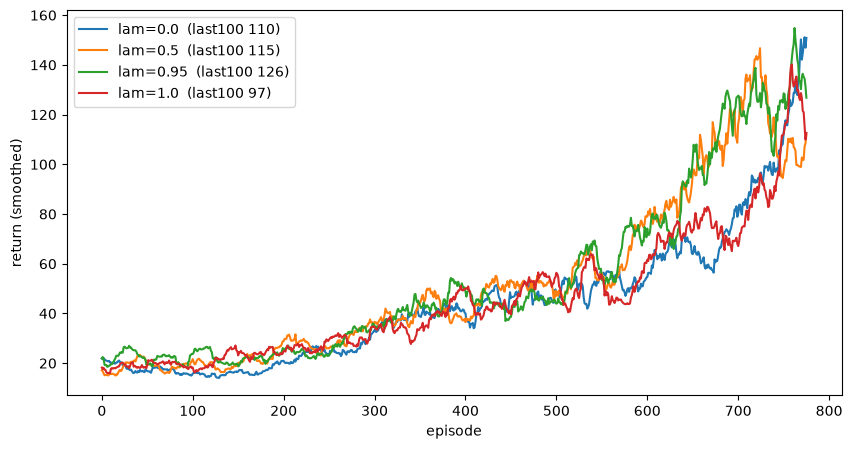

In [40]:
import matplotlib.pyplot as plt

def smooth(xs, k=25):
    return np.convolve(xs, np.ones(k) / k, mode="valid")

sweep = {}
for lam in [0.0, 0.5, 0.95, 1.0]:
    print(f"=== lam={lam} ===")
    _, _, lg = reinforce_baseline(n_episodes=800, lam=lam, lr=3e-4, lr_v=3e-3)
    sweep[lam] = lg

plt.figure(figsize=(10, 5))
for lam, lg in sweep.items():
    plt.plot(smooth(lg), label=f"lam={lam}  (last100 {np.mean(lg[-100:]):.0f})")
plt.xlabel("episode"); plt.ylabel("return (smoothed)"); plt.legend(); plt.show()
